# 01 — Dataset Inspection & Exploratory Data Analysis (EDA)

**Project:** LoanWise AI — Explainable AI-Powered Loan Eligibility & Risk Assessment System  
**Role:** Member 1 (ML Model Development)  
**Dataset:** Kaggle `altruistdelhite04/loan-prediction-problem-dataset` (placed locally in `data/raw/primary/`)

> **Rule:** Inspect the actual downloaded CSV first. Do not assume column names, value spellings, units, or row counts without running these cells.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Ensure project root (LoanWise-AI/) is importable regardless of where Jupyter starts
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.data_loader import (
    find_training_csv,
    find_unlabeled_test_csv,
    load_training_data,
    summarize_dataset,
)

sns.set_theme(style="whitegrid")
print("Project root:", PROJECT_ROOT)

Project root: /home/it/Downloads/LoanWise-AI/LoanWise-AI


## 1. Load & Verify Actual CSV Files

Locate the labeled training file (containing `Loan_Status`) and any unlabeled Kaggle test file inside `data/raw/primary/`.

In [2]:
train_csv_path = find_training_csv()
test_csv_path = find_unlabeled_test_csv()

print("Training CSV:", train_csv_path.name)
print("Unlabeled Test CSV:", test_csv_path.name if test_csv_path else "None found")

df = load_training_data(train_csv_path)
print("\nTraining shape (rows, columns):", df.shape)
print("Exact column names:", df.columns.tolist())
df.head()

Training CSV: train_u6lujuX_CVtuZ9i.csv
Unlabeled Test CSV: test_Y3wMUE5_7gLdaTN.csv

Training shape (rows, columns): (614, 13)
Exact column names: ['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
# Check data types and non-null counts
df.info()

# If unlabeled Kaggle test CSV exists, inspect its shape and columns too
if test_csv_path is not None:
    df_kaggle_test = pd.read_csv(test_csv_path)
    print("\nUnlabeled Kaggle test shape:", df_kaggle_test.shape)
    print("Unlabeled Kaggle test columns:", df_kaggle_test.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Unlabeled Kaggle test shape: (367, 12)
Unlabeled Kaggle test columns: ['Loan_ID', 'Gender', 'Married', 'Depende

## 2. Duplicates & Identifier Check

- Check exact duplicate rows (`df.duplicated().sum()`).
- Verify `Loan_ID` uniqueness (if present) so we confirm it is only an identifier to exclude from modeling.

In [4]:
dup_rows = int(df.duplicated().sum())
print(f"Exact duplicate rows: {dup_rows}")

if "Loan_ID" in df.columns:
    n_unique_ids = df["Loan_ID"].nunique(dropna=False)
    print(f"Unique Loan_ID values: {n_unique_ids} out of {len(df)} rows")
    if "Loan_ID" in df.columns and n_unique_ids == len(df):
        print("Confirmed: Loan_ID is a unique identifier and must be excluded from ML training.")

Exact duplicate rows: 0
Unique Loan_ID values: 614 out of 614 rows
Confirmed: Loan_ID is a unique identifier and must be excluded from ML training.


## 3. Missing-Value Analysis

Remember: Do **not** blindly drop all rows with missing values. Inspect how many values are missing per column so we can choose proper imputation strategies inside the scikit-learn pipeline.

,missing_count,missing_percent,dtype
Credit_History,50,8.14,float64
Self_Employed,32,5.21,object
LoanAmount,22,3.58,float64
Dependents,15,2.44,object
Loan_Amount_Term,14,2.28,float64
Gender,13,2.12,object
Married,3,0.49,object
Loan_ID,0,0.00,object
Education,0,0.00,object
ApplicantIncome,0,0.00,int64


Rows with >= 1 missing value: 134 / 614 (21.82%)


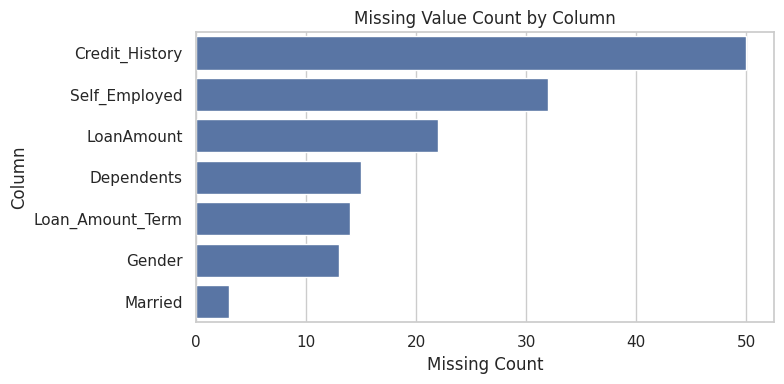

In [5]:
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str),
}).sort_values("missing_count", ascending=False)

display(missing_df)

rows_with_any_missing = int(df.isna().any(axis=1).sum())
print(f"Rows with >= 1 missing value: {rows_with_any_missing} / {len(df)} ({rows_with_any_missing / len(df) * 100:.2f}%)")

cols_with_missing = missing_df[missing_df["missing_count"] > 0]
if not cols_with_missing.empty:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.barplot(x=cols_with_missing["missing_count"], y=cols_with_missing.index, ax=ax, color="#4C72B0")
    ax.set_title("Missing Value Count by Column")
    ax.set_xlabel("Missing Count")
    ax.set_ylabel("Column")
    plt.tight_layout()
    plt.show()

## 4. Target Variable & Class Imbalance (`Loan_Status`)

,count,percent
Loan_Status,,
Y,422,68.73
N,192,31.27


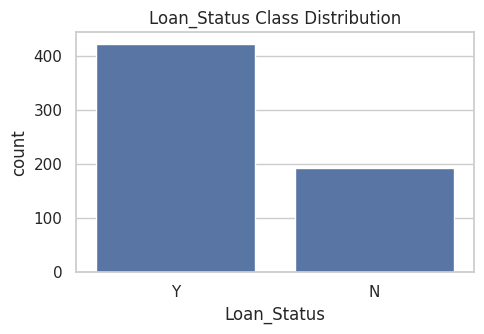

In [6]:
target_col = "Loan_Status"
if target_col in df.columns:
    target_counts = df[target_col].value_counts(dropna=False)
    target_pct = (df[target_col].value_counts(normalize=True, dropna=False) * 100).round(2)
    display(pd.DataFrame({"count": target_counts, "percent": target_pct}))

    fig, ax = plt.subplots(figsize=(5, 3.5))
    sns.countplot(data=df, x=target_col, order=target_counts.index, ax=ax)
    ax.set_title("Loan_Status Class Distribution")
    plt.tight_layout()
    plt.show()
else:
    print(f"Target column '{target_col}' not found in dataset.")

## 5. Categorical Features Inspection & Approval Rates

Verify exact category spellings (including spaces, casing, `"3+"` in `Dependents`, and `"Semiurban"` vs `"Semi-Urban"` in `Property_Area`) and inspect approval rates across subgroups (including demographic attributes for Responsible AI awareness).

In [7]:
cat_cols = [c for c in df.select_dtypes(include=["object", "category"]).columns if c not in {"Loan_ID", "Loan_Status"}]
print("Detected categorical columns (excluding Loan_ID & Loan_Status):", cat_cols)

for col in cat_cols:
    print(f"\n--- {col} ---")
    vc = df[col].value_counts(dropna=False)
    print(vc.to_string())
    if target_col in df.columns:
        rate = pd.crosstab(df[col].fillna("<MISSING>"), df[target_col], normalize="index").round(3) * 100
        print("Approval/Rejection % by category:")
        print(rate.to_string())

Detected categorical columns (excluding Loan_ID & Loan_Status): ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']

--- Gender ---
Gender
Male      489
Female    112
NaN        13
Approval/Rejection % by category:
Loan_Status     N     Y
Gender                 
<MISSING>    38.5  61.5
Female       33.0  67.0
Male         30.7  69.3

--- Married ---
Married
Yes    398
No     213
NaN      3
Approval/Rejection % by category:
Loan_Status     N      Y
Married                 
<MISSING>     0.0  100.0
No           37.1   62.9
Yes          28.4   71.6

--- Dependents ---
Dependents
0      345
1      102
2      101
3+      51
NaN     15


Approval/Rejection % by category:
Loan_Status     N     Y
Dependents             
0            31.0  69.0
1            35.3  64.7
2            24.8  75.2
3+           35.3  64.7
<MISSING>    40.0  60.0

--- Education ---
Education
Graduate        480
Not Graduate    134
Approval/Rejection % by category:
Loan_Status      N     Y
Education               
Graduate      29.2  70.8
Not Graduate  38.8  61.2

--- Self_Employed ---
Self_Employed
No     500
Yes     82
NaN     32
Approval/Rejection % by category:
Loan_Status       N     Y
Self_Employed            
<MISSING>      28.1  71.9
No             31.4  68.6
Yes            31.7  68.3

--- Property_Area ---
Property_Area
Semiurban    233
Urban        202
Rural        179
Approval/Rejection % by category:
Loan_Status       N     Y
Property_Area            
Rural          38.5  61.5
Semiurban      23.2  76.8
Urban          34.2  65.8


## 6. Numerical Features, Distributions, Units & Outlier Analysis (IQR)

- Inspect summary statistics (`min`, `median`, `mean`, `max`, `skew`).
- Check `Credit_History` unique values (often encoded numerically as `0.0` / `1.0` even though it represents a binary flag).
- Check IQR outliers without blindly deleting legitimate high-income records.
- Inspect `ApplicantIncome`, `CoapplicantIncome`, and `LoanAmount` scales before deciding on any ratio features.

In [8]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Detected numerical columns:", num_cols)

if num_cols:
    stats = df[num_cols].describe().T
    stats["skew"] = df[num_cols].skew().round(3)
    display(stats)

    # IQR outlier summary
    outlier_rows = []
    for col in num_cols:
        series = df[col].dropna()
        q1, q3 = series.quantile(0.25), series.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        n_outliers = int(((series < lower) | (series > upper)).sum())
        outlier_rows.append({
            "column": col,
            "Q1": round(float(q1), 2),
            "Q3": round(float(q3), 2),
            "IQR": round(float(iqr), 2),
            "lower_fence": round(float(lower), 2),
            "upper_fence": round(float(upper), 2),
            "iqr_outliers": n_outliers,
        })
    display(pd.DataFrame(outlier_rows))

Detected numerical columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']


,count,mean,std,min,25%,50%,75%,max,skew
ApplicantIncome,614.0,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.00,81000.0,6.540
CoapplicantIncome,614.0,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0,7.492
LoanAmount,592.0,146.412162,85.587325,9.0,100.0,128.0,168.00,700.0,2.678
Loan_Amount_Term,600.0,342.000000,65.120410,12.0,360.0,360.0,360.00,480.0,-2.362
Credit_History,564.0,0.842199,0.364878,0.0,1.0,1.0,1.00,1.0,-1.882


,column,Q1,Q3,IQR,lower_fence,upper_fence,iqr_outliers
0,ApplicantIncome,2877.5,5795.00,2917.50,-1498.75,10171.25,50
1,CoapplicantIncome,0.0,2297.25,2297.25,-3445.88,5743.12,18
2,LoanAmount,100.0,168.00,68.00,-2.00,270.00,39
3,Loan_Amount_Term,360.0,360.00,0.00,360.00,360.00,88
4,Credit_History,1.0,1.00,0.00,1.00,1.00,89


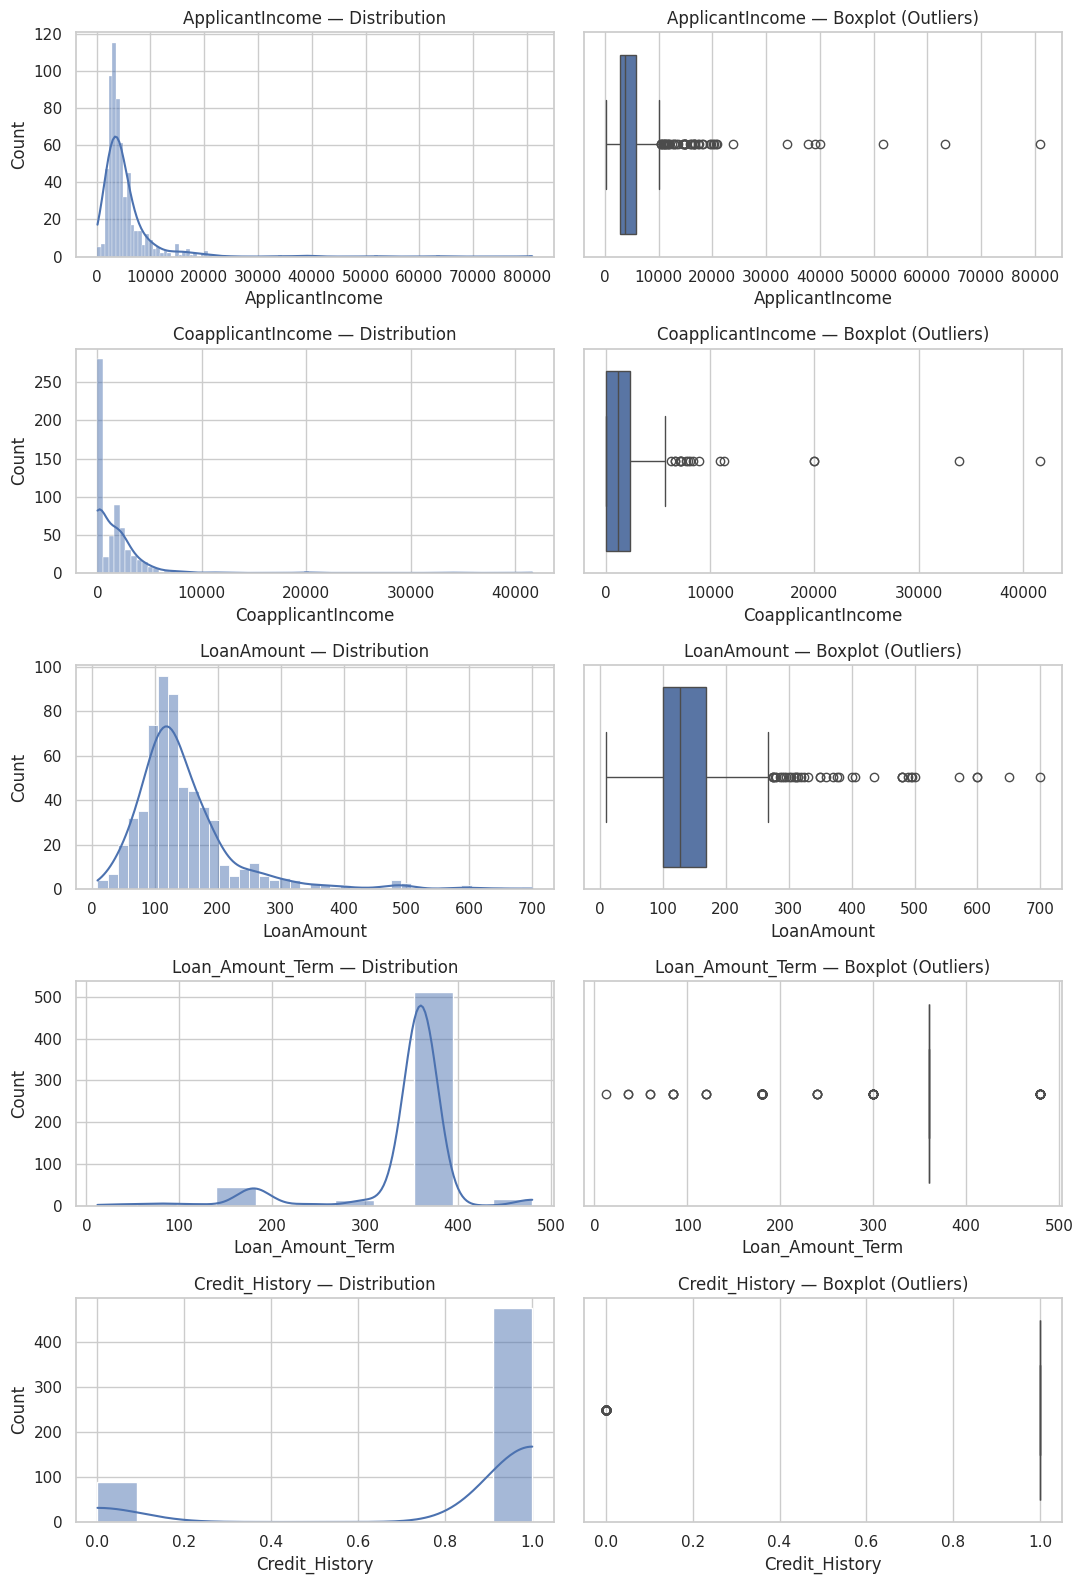

In [9]:
if num_cols:
    n_cols = len(num_cols)
    fig, axes = plt.subplots(n_cols, 2, figsize=(11, 3.2 * n_cols))
    if n_cols == 1:
        axes = np.array([axes])
    for idx, col in enumerate(num_cols):
        sns.histplot(df[col].dropna(), kde=True, ax=axes[idx, 0])
        axes[idx, 0].set_title(f"{col} — Distribution")
        sns.boxplot(x=df[col].dropna(), ax=axes[idx, 1])
        axes[idx, 1].set_title(f"{col} — Boxplot (Outliers)")
    plt.tight_layout()
    plt.show()

In [10]:
# Check Credit_History values and relationship with Loan_Status
if "Credit_History" in df.columns and target_col in df.columns:
    print("Credit_History unique values:", df["Credit_History"].unique().tolist())
    ct = pd.crosstab(df["Credit_History"].fillna(-1), df[target_col], margins=True)
    display(ct)

# Check ApplicantIncome + CoapplicantIncome scale vs LoanAmount
income_cols = [c for c in ["ApplicantIncome", "CoapplicantIncome", "LoanAmount", "Loan_Amount_Term"] if c in df.columns]
if income_cols:
    display(df[income_cols].quantile([0.0, 0.25, 0.5, 0.75, 0.95, 1.0]))

Credit_History unique values: [1.0, 0.0, nan]


Loan_Status,N,Y,All
Credit_History,,,
-1.0,13,37,50
0.0,82,7,89
1.0,97,378,475
All,192,422,614


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0.00,150.0,0.00,9.0,12.0
0.25,2877.5,0.00,100.0,360.0
0.50,3812.5,1188.50,128.0,360.0
0.75,5795.0,2297.25,168.0,360.0
0.95,14583.0,4997.40,297.8,360.0
1.00,81000.0,41667.00,700.0,480.0


## 7. EDA Summary Checklist (Fill In After Running)

After running all cells above on your local CSV, record the observed facts here before starting Step 3 (Preprocessing):
- **Verified train shape:** `TBD` rows × `TBD` columns
- **Exact duplicate rows:** `TBD`
- **Columns with missing values:** `TBD`
- **Class balance (`Loan_Status`):** `TBD`
- **Confirmed category values & any formatting quirks:** `TBD`
- **Confirmed scale of `ApplicantIncome`, `CoapplicantIncome`, `LoanAmount`:** `TBD`
- **Fairness note (`Gender`, `Married`):** Record observed historical approval rate differences and note that historical patterns may reflect dataset bias rather than fair creditworthiness.